# Imports

In [1]:
%load_ext autoreload
%autoreload 2

from CanterraFunctions import combustionProps, combustionPropsMethalox
import numpy as np
import matplotlib.pyplot as plt
import cantera as ct
from IPython.display import Image
import cea
from lookupGenerator import build_combustion_table, lookup_combustion_props



### Setup

In [2]:
sp = [s for s in ct.Species.list_from_file("nDodecane_Reitz.yaml")
      if set(s.composition) <= {"C", "H", "O"}]
GAS = ct.Solution(thermo="ideal-gas", species=sp)
GRAPHITE = ct.Solution("graphite.yaml")

MRRange = np.linspace(0.05, 4, 100)
chamberPs = [50, 100, 150]

# Baseline Equilibrium Properties

In [18]:
Ts     = np.zeros((len(chamberPs), len(MRRange)))
gammas = np.zeros_like(Ts)
Cps    = np.zeros_like(Ts)

for i, Pcc in enumerate(chamberPs):
    for j, MR in enumerate(MRRange):
        props = combustionProps(MR=MR, Pcc=Pcc, gas=GAS)
        Ts[i, j]     = props.T
        gammas[i, j] = props.gamma
        Cps[i, j]    = props.cp


c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3001.513323813797 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3017.9656455602667 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")


### Plots

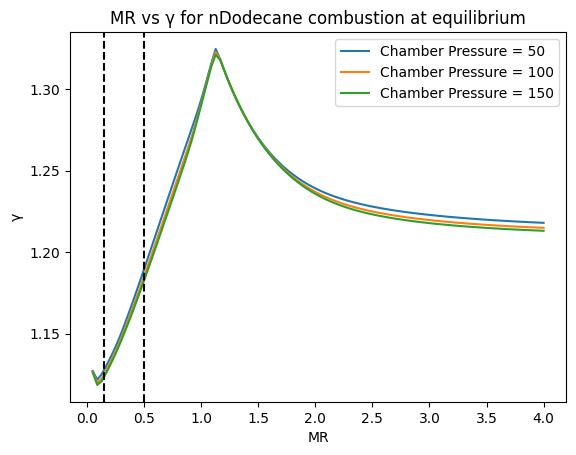

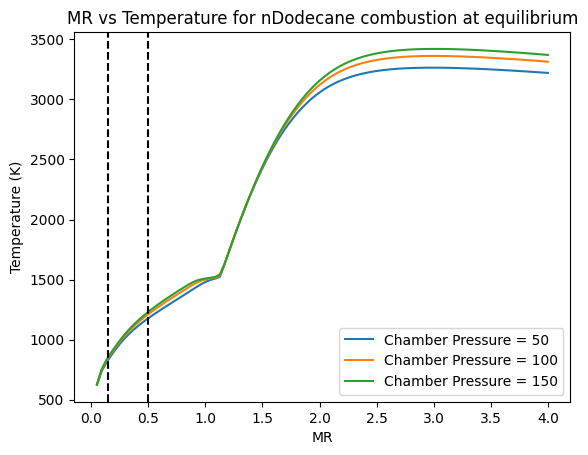

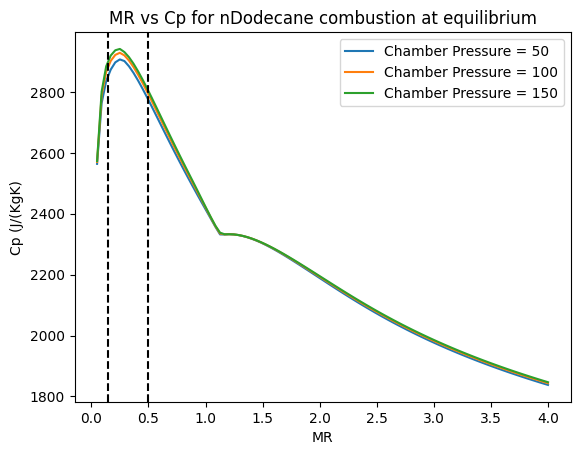

In [19]:
# Gamma plot
for i in range(len(chamberPs)):
    plt.plot(MRRange, gammas[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs \u03b3 for nDodecane combustion at equilibrium")
plt.xlabel("MR")
plt.ylabel("\u03b3")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')


# Temp plot
plt.figure()
for i in range(len(chamberPs)):
    plt.plot(MRRange, Ts[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs Temperature for nDodecane combustion at equilibrium")
plt.xlabel("MR")
plt.ylabel("Temperature (K)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')

# Cp plot
plt.figure()
for i in range(len(chamberPs)):
    plt.plot(MRRange, Cps[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs Cp for nDodecane combustion at equilibrium")
plt.xlabel("MR")
plt.ylabel("Cp (J/(KgK)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')


# Soot Modelled Properties 

In [31]:
sootTs     = np.zeros((len(chamberPs), len(MRRange)))
sootgammas = np.zeros_like(sootTs)
sootCps    = np.zeros_like(sootTs)

for i, Pcc in enumerate(chamberPs):
    for j, MR in enumerate(MRRange):
        props = combustionProps(MR=MR, Pcc=Pcc, soot=True, gas=GAS, graphite=GRAPHITE)
        sootTs[i, j]     = props.T
        sootgammas[i, j] = props.gamma
        sootCps[i, j]    = props.cp

### Plots

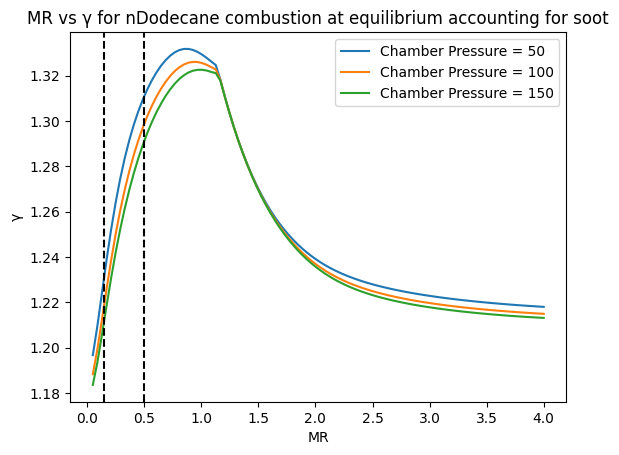

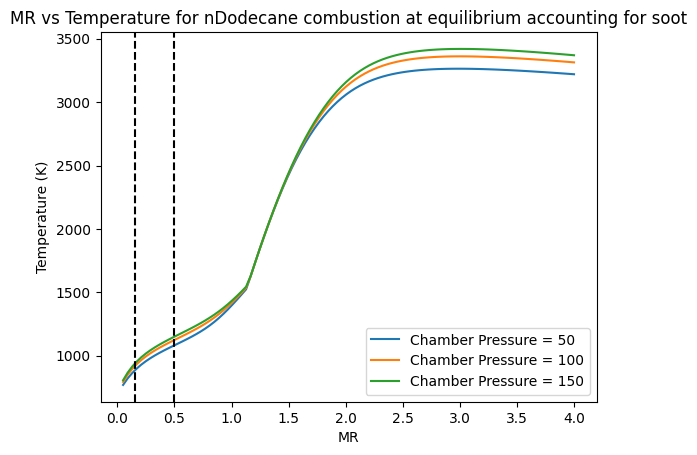

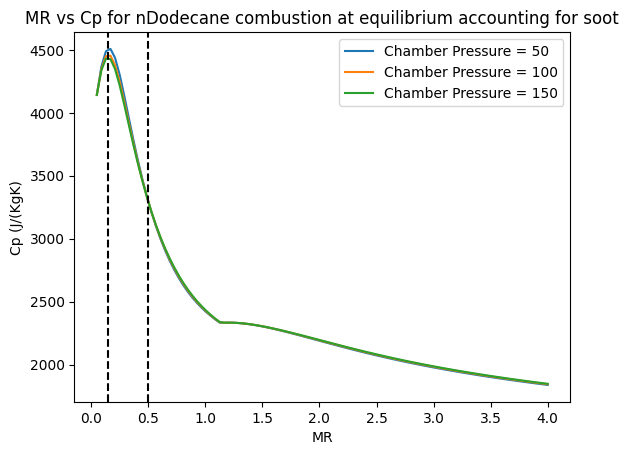

In [21]:
# Gamma plot
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootgammas[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs \u03b3 for nDodecane combustion at equilibrium accounting for soot")
plt.xlabel("MR")
plt.ylabel("\u03b3")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')


# Temp plot
plt.figure()
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootTs[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs Temperature for nDodecane combustion at equilibrium accounting for soot")
plt.xlabel("MR")
plt.ylabel("Temperature (K)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')

# Cp plot
plt.figure()
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootCps[i,:], label=f"Chamber Pressure = {chamberPs[i]}")
plt.title("MR vs Cp for nDodecane combustion at equilibrium accounting for soot")
plt.xlabel("MR")
plt.ylabel("Cp (J/(KgK)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')


# Comparison

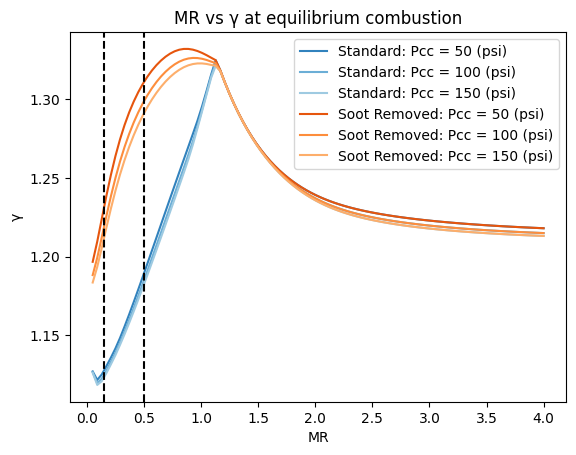

In [22]:
# gamma comparison
colors = plt.get_cmap('tab20c').colors   # tuple of 20 RGB colors
colors = plt.get_cmap('tab20c').colors
for i in range(len(chamberPs)):
    plt.plot(MRRange, gammas[i, :], label=f"Standard: Pcc = {chamberPs[i]} (psi)", color=colors[i])
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootgammas[i, :],     label=f"Soot Removed: Pcc = {chamberPs[i]} (psi)",     color=colors[i + 4])
plt.title("MR vs \u03b3 at equilibrium combustion")
plt.xlabel("MR")
plt.ylabel("\u03b3")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')

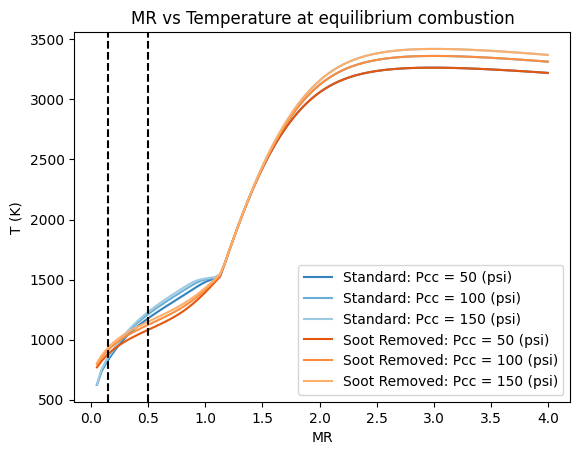

In [23]:
# T comparison
colors = plt.get_cmap('tab20c').colors   # tuple of 20 RGB colors
colors = plt.get_cmap('tab20c').colors
for i in range(len(chamberPs)):
    plt.plot(MRRange, Ts[i, :], label=f"Standard: Pcc = {chamberPs[i]} (psi)", color=colors[i])
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootTs[i, :],     label=f"Soot Removed: Pcc = {chamberPs[i]} (psi)",     color=colors[i + 4])
plt.title("MR vs Temperature at equilibrium combustion")
plt.xlabel("MR")
plt.ylabel("T (K)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')

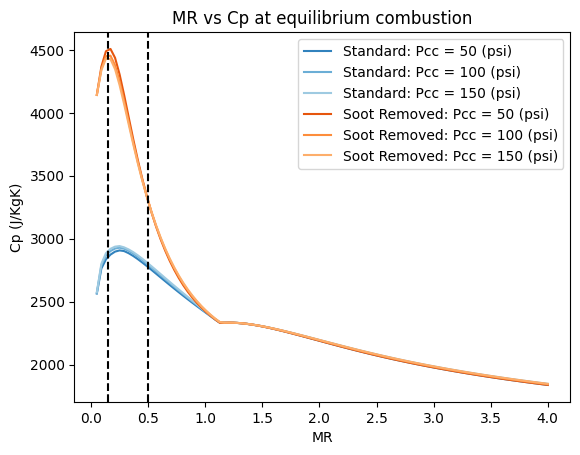

In [24]:
# Cp comparison
colors = plt.get_cmap('tab20c').colors   # tuple of 20 RGB colors
colors = plt.get_cmap('tab20c').colors
for i in range(len(chamberPs)):
    plt.plot(MRRange, Cps[i, :], label=f"Standard: Pcc = {chamberPs[i]} (psi)", color=colors[i])
for i in range(len(chamberPs)):
    plt.plot(MRRange, sootCps[i, :],     label=f"Soot Removed: Pcc = {chamberPs[i]} (psi)",     color=colors[i + 4])
plt.title("MR vs Cp at equilibrium combustion")
plt.xlabel("MR")
plt.ylabel("Cp (J/KgK)")
plt.legend()
plt.axvline(x=0.5, color='k', linestyle='--')
plt.axvline(x=0.15, color='k', linestyle='--')

# Soot Model vs Methalox

In [25]:
PCC = 60                          # [psi]

graphite = ct.Solution("graphite.yaml")
rp1_gas = ct.Solution("nDodecane_Reitz.yaml")
ch4_gas = ct.Solution("gri30.yaml")
 
MR_ST_RP1 = 18.5 * 32.00 / 170.34   # C12H26 + 18.5 O2  -> ≈ 3.48
MR_ST_CH4 = 2.0  * 32.00 / 16.04    # CH4 + 2 O2        -> ≈ 3.99

MR_rp1 = np.linspace(0.1, MR_ST_RP1, 50)
MR_ch4 = np.linspace(0.1, MR_ST_CH4, 50)

g_rp1 = np.array([combustionProps(m, PCC, True, rp1_gas, graphite).gamma for m in MR_rp1])
g_ch4 = np.array([combustionPropsMethalox(m, PCC, ch4_gas).gamma for m in MR_ch4])


c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:77: UserWarning: ChemEquil::equilibrate: Temperature (3007.965589058023 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")


### Plot

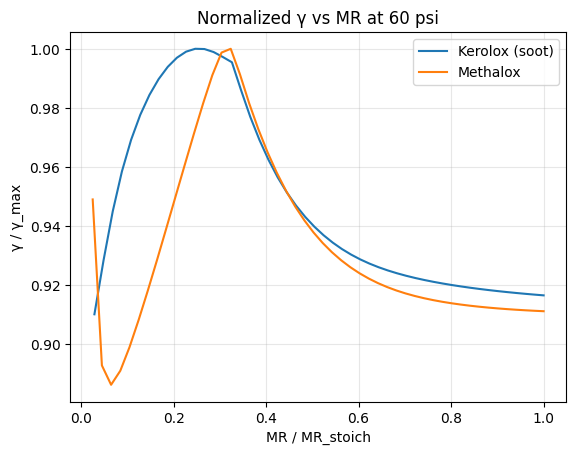

In [26]:
plt.plot(MR_rp1 / MR_ST_RP1, g_rp1 / g_rp1.max(), label="Kerolox (soot)")
plt.plot(MR_ch4 / MR_ST_CH4, g_ch4 / g_ch4.max(), label="Methalox")
plt.xlabel("MR / MR_stoich")
plt.ylabel("γ / γ_max")
plt.title(f"Normalized γ vs MR at {PCC} psi")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Model vs CEA

In [27]:
 # Must match what combustionProps uses
FUEL     = "RP-1"
OXIDIZER = "O2(L)"
T_REAC   = np.array([298.15, 298.1905])   # K, [fuel, oxidizer]
 
MRRange   = np.linspace(0.05, 4, 100)
chamberPs = [60]              # psi
 
# CEA setup
reac   = cea.Mixture([FUEL, OXIDIZER])
prod   = cea.Mixture([FUEL, OXIDIZER], products_from_reactants=True)
solver = cea.EqSolver(prod, reactants=reac)
sol    = cea.EqSolution(solver)
 
fuel_w = np.array([1.0, 0.0])
ox_w   = np.array([0.0, 1.0])
 
ceaGammas = np.zeros((len(chamberPs), len(MRRange)))
ceaTs     = np.zeros_like(ceaGammas)
sootGammas = np.zeros_like(ceaGammas)
sootlessGammas = np.zeros_like(ceaGammas)
 
for i, Pcc in enumerate(chamberPs):
    P_bar = cea.units.psi_to_bar(Pcc)
    for j, MR in enumerate(MRRange):
        w = reac.of_ratio_to_weights(ox_w, fuel_w, MR)
        h = reac.calc_property(cea.ENTHALPY, w, T_REAC) / cea.R
        solver.solve(sol, cea.HP, h, P_bar, w)
        ceaGammas[i, j] = sol.gamma_s
        ceaTs[i, j]     = sol.T
 
        props = combustionProps(MR=MR, Pcc=Pcc, soot=True, gas=GAS, graphite=GRAPHITE)
        props2 = combustionProps(MR=MR, Pcc=Pcc, soot=False, gas=GAS, graphite=GRAPHITE)
        sootGammas[i, j] = props.gamma
        sootlessGammas[i, j] = props2.gamma


c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3016.466330785944 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")


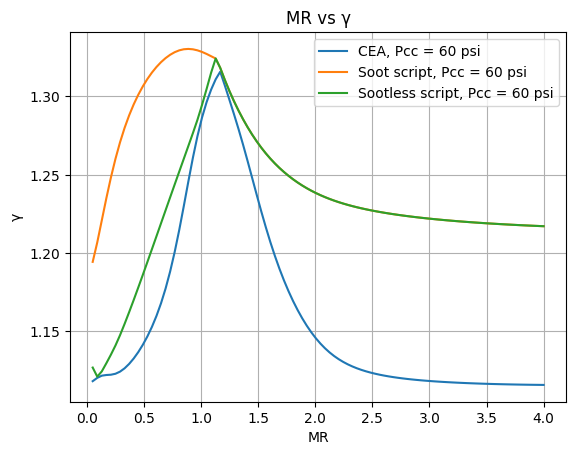

In [28]:
colors = plt.get_cmap("tab10").colors
for i, Pcc in enumerate(chamberPs):
    plt.plot(MRRange, ceaGammas[i],  color=colors[i], ls="-",  label=f"CEA, Pcc = {Pcc} psi")
    plt.plot(MRRange, sootGammas[i], color=colors[i+1], ls="-", label=f"Soot script, Pcc = {Pcc} psi")
    plt.plot(MRRange, sootlessGammas[i], color=colors[i+2], ls="-", label=f"Sootless script, Pcc = {Pcc} psi")
plt.xlabel("MR")
plt.ylabel("γ")
plt.title("MR vs γ")
plt.grid(True)
plt.legend()
plt.show()
 

# Lookup Table

c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3002.2594185700004 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3004.057993970498 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3005.8048924866634 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3007.502775241254 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitH

c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3003.3163836064664 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3007.113894616605 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3010.728665388489 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3014.176550294312 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHu

c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3005.673484241482 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3011.9212853981785 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3017.746825747495 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3023.2015254910148 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")


c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3004.6014426385314 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3013.880197915133 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3022.3350744197623 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")


c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3007.525770185658 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")
c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3019.596413067789 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")


c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3014.646482586058 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")


c:\Users\sakno\OneDrive\Documents\GitHub\YJSP Turbo Team\Turbopump\Gas Generator\CanterraFunctions.py:54: UserWarning: ChemEquil::equilibrate: Temperature (3015.619310769345 K) outside valid range of 300 K to 3000 K
  gas.equilibrate("HP")


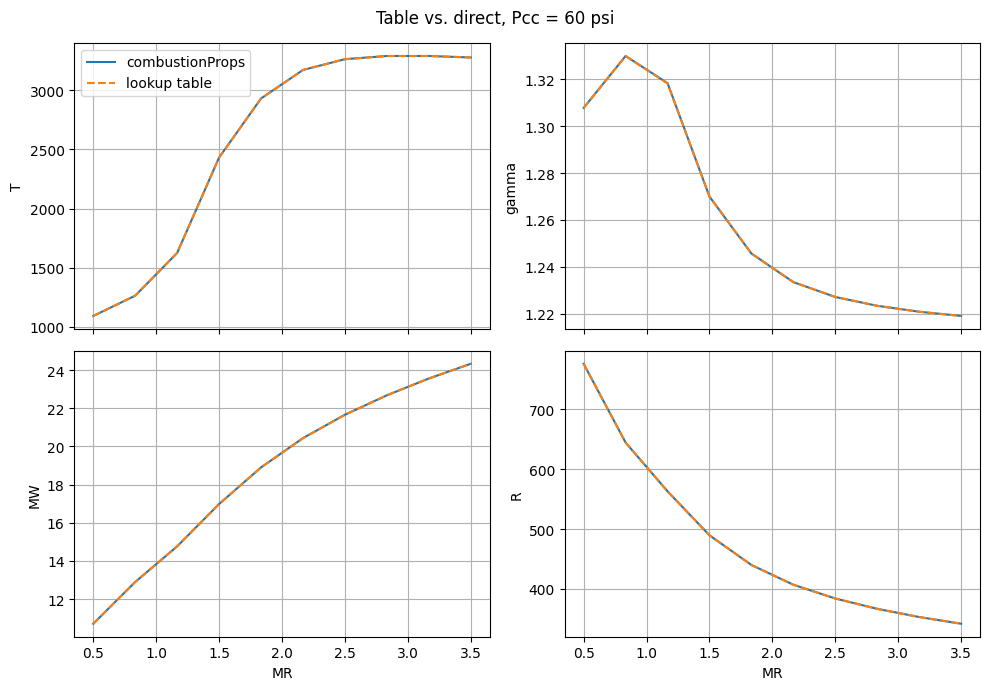

In [11]:
# 1) Build the table
MR_grid = np.linspace(.2, 3.5, 68)
Pcc_grid = np.linspace(15, 150, 56)
build_combustion_table(MR_grid, Pcc_grid, gas=GAS, filename="combProps.npz", soot=True)

# 2) Compare table vs. direct calls along MR at an off-grid pressure
Pcc_test = 60
MR_test = np.linspace(.5, 3.5, 10)



direct = [combustionProps(MR=mr, Pcc=Pcc_test, gas=GAS, soot=True, graphite=GRAPHITE) for mr in MR_test]
table = [lookup_combustion_props(MR=mr, Pcc=Pcc_test, filename="combProps.npz") for mr in MR_test]

# 3) Plot
props = ["T", "gamma", "MW", "R"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
for ax, p in zip(axes.flat, props):
    d = np.array([getattr(r, p) for r in direct])
    t = np.array([getattr(r, p) for r in table])
    ax.plot(MR_test, d, label="combustionProps")
    ax.plot(MR_test, t, "--", label="lookup table")
    ax.set_ylabel(p)
    ax.grid(True)
for ax in axes[1]:
    ax.set_xlabel("MR")
axes[0, 0].legend()
fig.suptitle(f"Table vs. direct, Pcc = {Pcc_test:g} psi")
plt.tight_layout()
plt.show()